# 02 · Chạy lại toàn bộ huấn luyện

Gắn output 01_DATA v4 vào Kaggle Input, bật GPU và Internet rồi chạy từ trên xuống. Cấu hình chạy CLIP, hai giai đoạn với ba seed, learning curve, ablation và fine-tune 180 ảnh. Checkpoint được chọn theo validation. Notebook 3 đọc output của lần huấn luyện đã chọn.


### Đọc kết quả huấn luyện

MobileNetV3 có 10 đầu ra: 9 tên con vật và `background`. Giai đoạn 1 chỉ học lớp cuối. Giai đoạn 2 mở thêm các block cuối. Sau mỗi epoch, mã đánh giá trên validation và lưu checkpoint khi chỉ số chọn mô hình cải thiện.

Bảng ba seed dùng để so hai giai đoạn. Giai đoạn 2 chuẩn đạt macro-F1 validation trung bình **92,38%**, so với **92,75%** của giai đoạn 1. Fine-tune thêm 180 ảnh là một thí nghiệm riêng, đạt **94,04%** trên validation.


# Notebook 2 Huấn luyện

Theo phần huấn luyện của file: CLIP baseline → DataLoader/augmentation → hai giai đoạn → ba seed → learning curve và ablation. Chỉ chạy sau khi dữ liệu Notebook 1 đủ và đã duyệt.

## Ghi chú báo cáo

**Vai trò.** Notebook huấn luyện MobileNetV3-Large và lưu checkpoint. Dùng output 01_DATA v4 trên Kaggle.

**Lượt chính.** V2 chạy 3 seed, CLIP zero-shot, learning curve và ablation. V3 tái dùng các output đó và fine-tune thêm 180 ảnh train theo các lỗi thường gặp. Checkpoint dùng trong Notebook 3 là `targeted_stage2.pth`, được chọn tại epoch 6 bằng val.

**Điểm cần trình bày.** Trung bình macro-F1 val của cấu hình chính là 92,75% ở giai đoạn 1 và 92,38% ở giai đoạn 2. Augmentation nhẹ ở giai đoạn 2 đạt 93,48% ở seed 42. Fine-tune 180 ảnh đạt 94,04% macro-F1 val ở lượt chọn checkpoint. V4 là thử nghiệm Goat riêng, có F1 không TTA bằng V3 trên test.

[Nguồn Kaggle, phiên bản 3](https://www.kaggle.com/code/ngaqyh/02-train?scriptVersionId=368347096)

## 01 Cài thư viện và cấu hình huấn luyện đầy đủ

Cấu hình theo file: MobileNetV3-Large ImageNet, batch32, stage1=10 epoch, stage2=25 epoch, seed41/42/43. Dùng GPU và AMP. Hàm seed giúp các lần chạy có thể so sánh.

**Giải thích cell.** Cấu hình 10 lớp, batch 32, seed 41/42/43, AMP và thống kê chuẩn hóa ImageNet. Thứ tự lớp phải khớp khi xuất Unity.

In [1]:
# Đặt đường dẫn, tham số, seed và cấu hình GPU. Seed của mỗi worker giúp cách lấy mẫu và biến đổi ảnh có thể tái lập tốt hơn.
import sys, subprocess
subprocess.check_call([
    sys.executable,
    '-m',
    'pip',
    'install',
    '-q',
    'open_clip_torch',
    'scikit-learn',
    'pandas',
    'pillow',
    'matplotlib'
])
from pathlib import Path
import os, json, random, math, io, copy, hashlib, shutil
import numpy as np, pandas as pd
from PIL import Image, ImageOps
import torch, torch.nn as nn
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
OUT = Path('/kaggle/working/animal_training')
OUT.mkdir(parents=True, exist_ok=True)
for d in ['checkpoints', 'metrics', 'charts']:
    (OUT / d).mkdir(exist_ok=True)
CLASSES = ['Dog', 'Cat', 'Horse', 'Sheep', 'Goat', 'Deer', 'Tiger', 'Penguin', 'Chicken', 'background']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
SEEDS = [41, 42, 43]
BATCH = 32
EPOCHS1 = 10
EPOCHS2 = 25
PATIENCE = 5
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
SIZE = 224
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Chọn GPU T4 trước khi chạy notebook huấn luyện'

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def worker_seed(worker_id):
    seed = torch.initial_seed() % 2 ** 32
    np.random.seed(seed)
    random.seed(seed)


## 02 Đọc dữ liệu đã xuất từ Notebook 1

Chỉ sửa đường dẫn DATA tới output Notebook 1 đã Add Input. Kiểm tra số ảnh, lớp, đường dẫn và split trước khi train. Không cần file release hay tự dò nhiều thư mục.

**Giải thích cell.** Kiểm tra mọi đường dẫn, giấy phép và ID, rồi tách train/val theo manifest. Dữ liệu 02_TRAIN dùng đúng output 01_DATA v4.

In [2]:
# Đọc CSV manifest, kiểm tra đường dẫn và chia dữ liệu theo split đã tạo. Giữ thứ tự lớp cố định để nhãn số nhất quán lúc xuất ONNX.
DATA = Path('/kaggle/input/notebooks/ngaqyh/01-data/animal_data')
manifest_path = DATA / 'dataset_manifest.csv'
assert manifest_path.is_file(), f'Không thấy manifest trong output 01_DATA: {manifest_path}'
df = pd.read_csv(manifest_path, dtype={'image_id': str})
df['path'] = df.relpath.map(lambda path: str(DATA / path))
assert df.path.map(lambda path: Path(path).is_file()).all(), 'Có đường dẫn ảnh không tồn tại'
assert df.image_id.is_unique, 'ID gốc xuất hiện nhiều lần'
assert df.license.notna().all(), 'Thiếu giấy phép ảnh'
for split, origin in [('train', 'train'), ('val', 'validation'), ('test', 'test')]:
    subset = df[df.split == split]
    counts = subset.groupby('label').size().reindex(CLASSES, fill_value=0)
    assert counts.min() > 0 and subset.official_split.eq(origin).all(), f'Sai lớp hoặc nguồn ở {split}'
    if split == 'train':
        assert counts.eq(200).all(), 'Train chưa đủ 200 ảnh/lớp'
    else:
        for label, count in counts[counts < 50].items():
            print(f'{split}/{label}: {count}/50 ảnh Open Images')
train_df = df[df.split == 'train'].reset_index(drop=True)
val_df = df[df.split == 'val'].reset_index(drop=True)
print(pd.crosstab(df.label, df.split))
shutil.copy2(manifest_path, OUT / 'data_manifest.csv')

val/Sheep: 19/50 ảnh Open Images
val/Goat: 30/50 ảnh Open Images
val/Tiger: 14/50 ảnh Open Images
val/Penguin: 31/50 ảnh Open Images
val/Chicken: 46/50 ảnh Open Images
test/Tiger: 34/50 ảnh Open Images
split       test  test_cartoon  train  val
label                                     
Cat           50            15    200   50
Chicken       50            15    200   46
Deer          50            15    200   50
Dog           50            15    200   50
Goat          50            10    200   30
Horse         50            15    200   50
Penguin       50            15    200   31
Sheep         50            15    200   19
Tiger         34            15    200   14
background    50             0    200   50


PosixPath('/kaggle/working/animal_training/data_manifest.csv')

## 03 Dataset tiền xử lý cố định và augmentation chỉ trên train

Dataset đọc ảnh và đổi nhãn sang số. DataLoader chia batch. Augmentation mạnh chỉ dùng train: crop, lật, xoay, màu, blur, JPEG và erasing. Val/test chỉ resize224×224 và normalize ImageNet, không center crop.

**Giải thích cell.** DataLoader ghép ảnh thành batch. Augmentation chỉ dùng cho train. Val/test resize 224×224 và chuẩn hóa theo ImageNet.

In [3]:
# DataLoader gom ảnh thành batch. Train có biến đổi ngẫu nhiên; validation/test dùng tiền xử lý cố định để so sánh công bằng.
class RandomJPEG:

    def __call__(self, im):
        if random.random() < 0.25:
            buff = io.BytesIO()
            im.save(buff, format='JPEG', quality=random.randint(50, 95))
            buff.seek(0)
            with Image.open(buff) as tmp:
                return tmp.convert('RGB').copy()
        return im
eval_tf = T.Compose([
    T.Resize((SIZE, SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

def train_tf(strong=True):
    if not strong:
        return T.Compose([
            T.Resize((SIZE, SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True),
            T.RandomHorizontalFlip(),
            T.ToTensor(),
            T.Normalize(MEAN, STD)
        ])
    return T.Compose([
        T.RandomResizedCrop(SIZE, scale=(0.5, 1.0), interpolation=InterpolationMode.BILINEAR),
        T.RandomHorizontalFlip(),
        T.RandomRotation(15),
        T.ColorJitter(0.15, 0.15, 0.15, 0.03),
        T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.0))], p=0.15),
        RandomJPEG(),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
        T.RandomErasing(p=0.15, scale=(0.02, 0.08), ratio=(0.5, 2.0))
    ])

class Animals(Dataset):

    def __init__(self, frame, tf):
        self.frame = frame.reset_index(drop=True)
        self.tf = tf

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        r = self.frame.iloc[i]
        with Image.open(r.path) as im:
            x = self.tf(ImageOps.exif_transpose(im).convert('RGB'))
        return (x, CLASS_TO_IDX[r.label])

def loader(frame, train=False, strong=True, seed=42):
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(
        Animals(frame, train_tf(strong) if train else eval_tf),
        batch_size=BATCH,
        shuffle=train,
        num_workers=2,
        pin_memory=True,
        worker_init_fn=worker_seed,
        generator=gen
    )

def fraction_frame(frac, seed):
    return pd.concat([g.sample(frac=1, random_state=seed).head(max(1, int(len(g) * frac))) for _, g in train_df.groupby('label')]).reset_index(drop=True)


## 04 CLIP zero shot trên val và test chạy trước huấn luyện

Chạy CLIP zero-shot trên val/test trước khi train để có baseline. Background dùng prompt riêng vì đây không phải một loài. Lưu logits và kết quả để so sánh cuối.

**Giải thích cell.** CLIP là baseline ngoài. Lưu dự đoán trên val/test để Notebook 3 so sánh cùng ảnh và thứ tự ID.

In [4]:
# Đo baseline CLIP zero-shot bằng cách so embedding ảnh với prompt của từng lớp; bước này không cập nhật trọng số.
import open_clip
clip, _, clip_tf = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai', device=DEVICE)
clip.eval()
tokenizer = open_clip.get_tokenizer('ViT-B-32')
prompts = [f'a photo of a {c.lower()}' for c in CLASSES[:-1]] + ['a photo of scenery, an object, or an animal other than a dog, cat, horse, sheep, goat, deer, tiger, penguin or chicken']
with torch.inference_mode():
    text = clip.encode_text(tokenizer(prompts).to(DEVICE))
    text = text / text.norm(dim=-1, keepdim=True)
for split in ['val', 'test']:
    sub = df[df.split == split].reset_index(drop=True)
    zs = []
    ys = []
    dl = DataLoader(Animals(sub, clip_tf), batch_size=BATCH, num_workers=2)
    with torch.inference_mode():
        for x, y in dl:
            v = clip.encode_image(x.to(DEVICE))
            v = v / v.norm(dim=-1, keepdim=True)
            zs.append((clip.logit_scale.exp() * v @ text.T).float().cpu().numpy())
            ys.extend(y.tolist())
    z = np.concatenate(zs)
    y = np.array(ys)
    np.savez(OUT / 'metrics' / f'clip_{split}.npz', logits=z, y=y, image_ids=sub.image_id.to_numpy(dtype=str))
    report = classification_report(
        y,
        z.argmax(1),
        labels=list(range(10)),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )
    (OUT / 'metrics' / f'clip_{split}.json').write_text(json.dumps(report, indent=2))
    print('CLIP', split, accuracy_score(y, z.argmax(1)), f1_score(y, z.argmax(1), average='macro'))
del clip
torch.cuda.empty_cache()


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP val 0.9076923076923077 0.8942784277578092
CLIP test 0.9008264462809917 0.8947158944796388


## 05 MobileNetV3 pretrained head Dropout 0.2 Linear 10
Giai đoạn 1 chỉ train lớp cuối. Giai đoạn 2 mở ba block cuối, lớp chiếu và classifier, đồng thời giữ thống kê BatchNorm. Warmup 1 epoch rồi cosine, dừng sớm theo macro-F1 trên val với patience 5.

**Giải thích cell.** Giai đoạn 1 chỉ học lớp cuối. Giai đoạn 2 mở ba block cuối, lớp chiếu và classifier, giữ thống kê BatchNorm, warmup/cosine và dừng sớm theo macro-F1 val.

In [5]:
# Tạo MobileNetV3, tính chỉ số validation và huấn luyện hai giai đoạn. Sau mỗi epoch, giữ lại checkpoint có macro-F1 validation cao nhất.
# Giữ phần trích đặc trưng đã học từ ImageNet và thay lớp cuối bằng đầu ra 10 lớp.
def build(pretrained=True):
    model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Sequential(nn.Dropout(0.2), nn.Linear(in_features, NUM_CLASSES))
    return model

@torch.inference_mode()
def evaluate(model, dl):
    model.eval()
    zs = []
    ys = []
    for x, y in dl:
        z = model(x.to(DEVICE))
        zs.append(z.float().cpu().numpy())
        ys.extend(y.tolist())
    z = np.concatenate(zs)
    y = np.array(ys)
    p = z.argmax(1)
    return dict(
        accuracy=float(accuracy_score(y, p)),
        macro_f1=float(f1_score(y, p, labels=list(range(10)), average='macro', zero_division=0)),
        top3=float(np.mean(np.any(np.argsort(z, axis=1)[:, -3:] == y[:, None], axis=1)))
    )

# Stage 1 chỉ train lớp cuối; stage 2 mở thêm các block cuối với learning rate nhỏ hơn đầu phân loại.
def fit(model, tr, val, stage, seed, name, strong=True, mixup=0.0):
    model = model.to(DEVICE)
    if stage == 1:
        for p in model.parameters():
            p.requires_grad = False
        for p in model.classifier[-1].parameters():
            p.requires_grad = True
        opt = torch.optim.AdamW(model.classifier[-1].parameters(), lr=0.001)
        epochs = EPOCHS1
    else:
        for p in model.parameters():
            p.requires_grad = False
        # Ba block cuối và lớp chiếu ngay trước classifier.
        last_features = model.features[-4:]
        for p in last_features.parameters():
            p.requires_grad = True
        for p in model.classifier.parameters():
            p.requires_grad = True
        opt = torch.optim.AdamW([
            {'params': last_features.parameters(), 'lr': 0.0001},
            {'params': model.classifier.parameters(), 'lr': 0.001},
        ])
        epochs = EPOCHS2
    dl = loader(tr, train=True, strong=strong, seed=seed)
    vd = loader(val)
    scaler = torch.amp.GradScaler('cuda')
    best = -1.0
    bad = 0
    history = []
    path = OUT / 'checkpoints' / f'{name}_stage{stage}.pth'
    base_lrs = [g['lr'] for g in opt.param_groups]
    global_step = 0
    for epoch in range(epochs):
        model.train()
        if stage == 1:
            model.features.eval()
            model.classifier.eval()
            model.classifier[-1].train()
        else:
            # Giữ thống kê BatchNorm của baseline để fine-tune ổn định hơn.
            for layer in model.features.modules():
                if isinstance(layer, nn.BatchNorm2d):
                    layer.eval()
        losses = []
        for x, y in dl:
            if stage == 2:
                # Tăng learning rate trong epoch đầu, sau đó giảm theo cosine để cập nhật nhẹ dần.
                if global_step < len(dl):
                    fac = (global_step + 1) / len(dl)
                else:
                    t = (global_step - len(dl)) / max(1, (epochs - 1) * len(dl) - 1)
                    fac = 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1, t)))
                for g, lr in zip(opt.param_groups, base_lrs):
                    g['lr'] = lr * fac
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            # Xóa gradient cũ trước batch mới để không cộng dồn qua các batch.
            opt.zero_grad(set_to_none=True)
            if mixup > 0:
                lam = float(np.random.beta(mixup, mixup))
                perm = torch.randperm(len(x), device=DEVICE)
                x = lam * x + (1 - lam) * x[perm]
            # AMP giảm chi phí tính toán trên GPU. GradScaler giữ gradient nhỏ khỏi bị làm tròn về 0.
            with torch.amp.autocast('cuda'):
                z = model(x)
                loss = nn.functional.cross_entropy(z, y, label_smoothing=0.1)
                if mixup > 0:
                    loss = lam * loss + (1 - lam) * nn.functional.cross_entropy(
                        z,
                        y[perm],
                        label_smoothing=0.1
                    )
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            losses.append(loss.detach().item())
            global_step += 1
        met = evaluate(model, vd)
        met.update(epoch=epoch + 1, train_loss=float(np.mean(losses)), lr_head=opt.param_groups[-1]['lr'])
        history.append(met)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f'{name} | giai đoạn {stage} | epoch {epoch + 1} | macro-F1 val {met["macro_f1"]:.2%}', flush=True)
        # Chỉ ghi đè file .pth khi validation cải thiện. File giữ trọng số và metadata; không lưu trạng thái optimizer/AMP.
        if met['macro_f1'] > best + 1e-06:
            best = met['macro_f1']
            bad = 0
            torch.save(dict(
                state_dict={k: v.cpu() for k, v in model.state_dict().items()},
                classes=CLASSES,
                arch='mobilenet_v3_large',
                seed=seed,
                stage=stage,
                val_metrics=met,
                mean=MEAN,
                std=STD,
                size=SIZE
            ), path)
        else:
            bad += 1
        pd.DataFrame(history).to_csv(OUT / 'metrics' / f'{name}_stage{stage}_history.csv', index=False)
        # Dừng stage 2 khi validation không cải thiện đủ số epoch liên tiếp.
        if stage == 2 and bad >= PATIENCE:
            break
    # Khôi phục trọng số của epoch tốt nhất trước khi trả mô hình cho bước sau.
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)['state_dict'])
    return (model, best, path)


## 06 Hai giai đoạn với ba seed lưu baseline và trung bình độ lệch chuẩn

Chạy cả hai giai đoạn cho ba seed. Mỗi lần lưu checkpoint stage1 và stage2. Báo mean±std và chọn checkpoint bằng val F1, không chọn bằng test.

**Giải thích cell.** Chạy cả hai giai đoạn cho ba seed. Lưu baseline, checkpoint tốt nhất và trung bình ± độ lệch chuẩn qua seed.

In [6]:
# Chạy ba seed để xem kết quả ổn định đến đâu. Chọn lần chạy bằng validation; giữ test cho đánh giá.
results = []

def experiment(name, seed=42, frac=1.0, strong=True, mixup=0.0):
    seed_all(seed)
    sub = fraction_frame(frac, seed)
    model = build(pretrained=True)
    model, b1, p1 = fit(model, sub, val_df, 1, seed, name, strong=strong)
    seed_all(seed)
    model, b2, p2 = fit(model, sub, val_df, 2, seed, name, strong=strong, mixup=mixup)
    del model
    torch.cuda.empty_cache()
    return dict(
        name=name,
        seed=seed,
        fraction=frac,
        strong=strong,
        mixup=mixup,
        stage1_f1=b1,
        stage2_f1=b2,
        stage1=p1.name,
        stage2=p2.name
    )
for seed in SEEDS:
    results.append(experiment(f'seed_{seed}', seed=seed))
    pd.DataFrame(results).to_csv(OUT / 'metrics' / 'experiments.csv', index=False)
seed_results = pd.DataFrame(results)
print(seed_results[['stage1_f1', 'stage2_f1']].agg(['mean', 'std']))
seed_results[['stage1_f1', 'stage2_f1']].agg(['mean', 'std']).to_csv(OUT / 'metrics' / 'seed_summary_val.csv')
best = seed_results.sort_values(['stage2_f1', 'seed'], ascending=[False, True]).iloc[0]
shutil.copy2(OUT / 'checkpoints' / best.stage2, OUT / 'checkpoints' / 'selected_stage2.pth')
shutil.copy2(OUT / 'checkpoints' / best.stage1, OUT / 'checkpoints' / 'selected_stage1.pth')


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 110MB/s]


seed_41 | giai đoạn 1 | epoch 1 | macro-F1 val 85.70%
seed_41 | giai đoạn 1 | epoch 5 | macro-F1 val 91.55%
seed_41 | giai đoạn 1 | epoch 10 | macro-F1 val 93.03%
seed_41 | giai đoạn 2 | epoch 1 | macro-F1 val 91.10%
seed_41 | giai đoạn 2 | epoch 5 | macro-F1 val 90.55%
seed_41 | giai đoạn 2 | epoch 10 | macro-F1 val 91.64%
seed_41 | giai đoạn 2 | epoch 15 | macro-F1 val 91.49%
seed_41 | giai đoạn 2 | epoch 20 | macro-F1 val 91.62%
seed_42 | giai đoạn 1 | epoch 1 | macro-F1 val 83.79%
seed_42 | giai đoạn 1 | epoch 5 | macro-F1 val 91.18%
seed_42 | giai đoạn 1 | epoch 10 | macro-F1 val 92.83%
seed_42 | giai đoạn 2 | epoch 1 | macro-F1 val 91.62%
seed_42 | giai đoạn 2 | epoch 5 | macro-F1 val 91.10%
seed_43 | giai đoạn 1 | epoch 1 | macro-F1 val 84.50%
seed_43 | giai đoạn 1 | epoch 5 | macro-F1 val 89.80%
seed_43 | giai đoạn 1 | epoch 10 | macro-F1 val 92.38%
seed_43 | giai đoạn 2 | epoch 1 | macro-F1 val 91.60%
seed_43 | giai đoạn 2 | epoch 5 | macro-F1 val 92.67%
seed_43 | giai đoạn 2 

PosixPath('/kaggle/working/animal_training/checkpoints/selected_stage1.pth')

## 07 Learning curve 25 50 100 phần trăm và ablation augmentation mixup
Learning curve dùng 25%, 50% và 100% ảnh train. Hai ablation dùng cùng checkpoint giai đoạn 1, tập train và seed của baseline. Mỗi ablation chỉ đổi một yếu tố ở giai đoạn 2, gồm augmentation nhẹ hoặc Mixup.

**Giải thích cell.** Learning curve dùng 25%, 50% và 100% train. Hai ablation dùng cùng checkpoint giai đoạn 1 của seed 42 và đổi riêng augmentation hoặc Mixup ở giai đoạn 2.

In [7]:
# So learning curve 25%, 50%, 100% và các cách augmentation. Giữ cùng validation để quan sát ảnh hưởng của từng thay đổi.
for frac in [0.25, 0.5]:
    results.append(experiment(f'curve_{int(frac * 100)}', seed=42, frac=frac))
    pd.DataFrame(results).to_csv(OUT / 'metrics' / 'experiments.csv', index=False)

# Hai thí nghiệm dùng đúng checkpoint stage 1 của baseline seed 42.
seed42 = seed_results[seed_results.seed == 42].iloc[0]
start_path = OUT / 'checkpoints' / seed42.stage1
start = torch.load(start_path, map_location='cpu', weights_only=False)
same_train = fraction_frame(1.0, 42)
for name, strong, mixup in [('ablation_light', False, 0.0), ('ablation_mixup', True, 0.2)]:
    m = build(False)
    m.load_state_dict(start['state_dict'])
    seed_all(42)
    m, score, path = fit(m, same_train, val_df, 2, 42, name, strong=strong, mixup=mixup)
    results.append(dict(
        name=name, seed=42, fraction=1.0, strong=strong, mixup=mixup,
        stage1_f1=seed42.stage1_f1, stage2_f1=score,
        stage1=start_path.name, stage2=path.name,
    ))
    pd.DataFrame(results).to_csv(OUT / 'metrics' / 'experiments.csv', index=False)
    del m
    torch.cuda.empty_cache()

print(pd.DataFrame(results).query('seed == 42 and fraction == 1')[
    ['name', 'stage1_f1', 'stage2_f1']
].to_string(index=False))

curve_25 | giai đoạn 1 | epoch 1 | macro-F1 val 67.32%
curve_25 | giai đoạn 1 | epoch 5 | macro-F1 val 82.29%
curve_25 | giai đoạn 1 | epoch 10 | macro-F1 val 83.71%
curve_25 | giai đoạn 2 | epoch 1 | macro-F1 val 86.82%
curve_25 | giai đoạn 2 | epoch 5 | macro-F1 val 85.99%
curve_50 | giai đoạn 1 | epoch 1 | macro-F1 val 77.65%
curve_50 | giai đoạn 1 | epoch 5 | macro-F1 val 87.21%
curve_50 | giai đoạn 1 | epoch 10 | macro-F1 val 88.48%
curve_50 | giai đoạn 2 | epoch 1 | macro-F1 val 88.10%
curve_50 | giai đoạn 2 | epoch 5 | macro-F1 val 90.63%
curve_50 | giai đoạn 2 | epoch 10 | macro-F1 val 91.22%
curve_50 | giai đoạn 2 | epoch 15 | macro-F1 val 90.94%
ablation_light | giai đoạn 2 | epoch 1 | macro-F1 val 90.44%
ablation_light | giai đoạn 2 | epoch 5 | macro-F1 val 92.42%
ablation_mixup | giai đoạn 2 | epoch 1 | macro-F1 val 88.33%
ablation_mixup | giai đoạn 2 | epoch 5 | macro-F1 val 90.61%
          name  stage1_f1  stage2_f1
       seed_42     0.9283   0.916197
ablation_light    

## 08 Biểu đồ learning curve và cấu hình tái lập

Lưu biểu đồ và cấu hình tiền xử lý/lớp để Notebook 3 và Unity dùng thống nhất. Save Version giữ checkpoint và output.

**Giải thích cell.** Lưu learning curve và cấu hình tái lập cho Notebook 3. Các tệp đã được mang từ lượt V2 sang output V3.

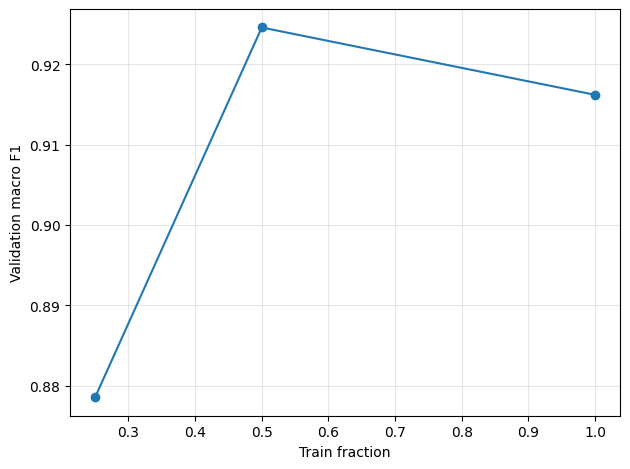

Save Version; Notebook 3 dùng output: /kaggle/working/animal_training


In [8]:
# Ghi cấu hình huấn luyện, bảng chỉ số và biểu đồ để biết kết quả nào tương ứng với từng lần chạy.
import matplotlib.pyplot as plt
exp = pd.DataFrame(results)
curve = exp[exp.name.isin(['curve_25', 'curve_50', 'seed_42'])].sort_values('fraction')
plt.plot(curve.fraction, curve.stage2_f1, 'o-')
plt.xlabel('Train fraction')
plt.ylabel('Validation macro F1')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / 'charts' / 'learning_curve.png', dpi=160)
plt.show()
config = dict(
    classes=CLASSES,
    class_to_idx=CLASS_TO_IDX,
    seeds=SEEDS,
    batch=BATCH,
    epochs_stage1=EPOCHS1,
    epochs_stage2=EPOCHS2,
    patience=PATIENCE,
    selected_seed=int(best.seed),
    mean=MEAN,
    std=STD,
    input_size=[1, 3, 224, 224],
    resize='PIL bilinear antialias Resize((224,224))',
    exif='transpose before RGB',
    channel_order='RGB',
    layout='NCHW',
    label_smoothing=0.1,
    pretrained='IMAGENET1K_V2',
    dataset_root=str(DATA),
    stage2_features='last three inverted residual blocks and final projection',
    stage2_batchnorm='running statistics frozen'
)
(OUT / 'training_config.json').write_text(json.dumps(config, indent=2))
print('Save Version; Notebook 3 dùng output:', OUT)


**Giải thích cell.** Fine-tune có mục tiêu với 50 Tiger, 50 background, 40 Goat, 20 Sheep, 20 Deer. Chỉ lấy ảnh train dự phòng chưa dùng đã qua lọc/duyệt. Chọn epoch theo val và lưu danh sách ảnh có nguồn, ID và giấy phép.

In [9]:
# Fine-tune có mục tiêu: lấy ảnh khó từ phần train dự phòng, ưu tiên các lớp dễ nhầm. Chọn epoch bằng điểm tổng hợp trên validation.
# Fine-tune có mục tiêu sau khi đọc confusion matrix.
from collections import Counter
from torch.nn import functional as F

start_path = OUT / 'checkpoints' / 'ablation_light_stage2.pth'
assert start_path.is_file(), 'Chạy cell ablation augmentation nhẹ trước.'
start = torch.load(start_path, map_location='cpu', weights_only=False)
assert start['classes'] == CLASSES
assert (DATA / 'dataset_manifest.csv').read_bytes() == (OUT / 'data_manifest.csv').read_bytes()

focus = {
    'Tiger': (50, ['background', 'Cat']),
    'Goat': (40, ['Deer', 'Sheep']),
    'Sheep': (20, ['Goat']),
    'Deer': (20, ['Goat']),
    'background': (50, ['Dog', 'Deer', 'Chicken', 'Sheep']),
}
# Chỉ bổ sung ảnh từ split train gốc, chưa nằm trong manifest và đã qua các kiểm tra dữ liệu.
used = set(df.image_id)
records = json.loads((DATA / 'fiftyone_dataset.json').read_text())['samples']
rows = []
for s in records:
    tags = s.get('tags', [])
    if (s.get('split') != 'train' or s.get('official_split') != 'train'
        or s.get('label') not in focus or s.get('original_id') in used
        or s.get('duplicate') is not False or s.get('too_small') is not False
        or s.get('depiction') or 'loai' in tags):
        continue
    if (s.get('clip_disagree') or s['label'] == 'background') and 'giu' not in tags:
        continue
    image_id = s['original_id']
    rows.append(dict(image_id=image_id, label=s['label'], source=s['source'],
                     official_split='train', background_kind=s.get('background_kind'),
                     path=str(DATA / 'processed' / f'{image_id}.jpg'), phash=s['processed_phash']))
reserve = pd.DataFrame(rows).drop_duplicates('image_id').sort_values('image_id').reset_index(drop=True)
assert reserve.path.map(lambda p: Path(p).is_file()).all()
assert used.isdisjoint(reserve.image_id)
print('Ảnh train dự phòng:', dict(Counter(reserve.label)), flush=True)

@torch.inference_mode()
def predict_frame(model, frame):
    model.eval()
    logits, labels = [], []
    for x, y in loader(frame):
        logits.append(model(x.to(DEVICE)).cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels).numpy()

model = build(False).to(DEVICE)
model.load_state_dict(start['state_dict'])
z, _ = predict_frame(model, reserve)
p = z.softmax(1).numpy()
new_rows = []
for label, (count, confusions) in focus.items():
    pool = reserve[reserve.label == label].copy()
    own = CLASS_TO_IDX[label]
    confused = [CLASS_TO_IDX[c] for c in confusions]
    # Điểm càng lớn khi mô hình nghiêng về lớp dễ nhầm hơn lớp thật.
    pool['difficulty'] = p[pool.index][:, confused].max(1) - p[pool.index, own]
    groups = [(pool, count)] if label != 'background' else [
        (pool[pool.background_kind == 'hard_negative'], 40),
        (pool[pool.background_kind == 'object'], 10),
    ]
    for group, n in groups:
        assert len(group) >= n, f'Thiếu ảnh dự phòng: {label}'
        hard = group.nlargest(2 * n // 3, 'difficulty')
        rest = group.drop(hard.index).sample(n=n - len(hard), random_state=42)
        new_rows.extend([hard, rest])
extra = pd.concat(new_rows, ignore_index=True)
meta_path = DATA / 'fiftyone_zoo/open-images-v7/train/metadata/image_ids.csv'
ids = set(extra.image_id)
metadata = []
for chunk in pd.read_csv(meta_path, usecols=['ImageID', 'License', 'OriginalURL'], dtype=str, chunksize=100_000):
    metadata.append(chunk[chunk.ImageID.isin(ids)])
metadata = pd.concat(metadata).drop_duplicates('ImageID').rename(columns={
    'ImageID': 'image_id', 'License': 'license', 'OriginalURL': 'original_url'})
extra = extra.merge(metadata, on='image_id', validate='one_to_one', how='left')
assert len(extra) == 180 and extra.license.notna().all()
extra.drop(columns='path').to_csv(OUT / 'metrics' / 'targeted_train_additions.csv', index=False)
print('Ảnh bổ sung:', extra.label.value_counts().to_dict(), flush=True)


def focus_metrics(model):
    z, y = predict_frame(model, val_df)
    predicted = z.argmax(1).numpy()
    f1 = f1_score(y, predicted, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    bg = y == CLASS_TO_IDX['background']
    result = dict(macro_f1=float(f1.mean()), background_recall=float((predicted[bg] == CLASS_TO_IDX['background']).mean()),
                  tiger_f1=float(f1[CLASS_TO_IDX['Tiger']]), goat_f1=float(f1[CLASS_TO_IDX['Goat']]))
    # Một nửa điểm từ macro-F1 toàn bộ lớp, một nửa từ ba chỉ số cần cải thiện.
    result['score'] = 0.5 * result['macro_f1'] + 0.5 * np.mean([result['background_recall'], result['tiger_f1'], result['goat_f1']])
    return result

seed_all(42)
before = focus_metrics(model)
print('Val trước fine-tune:', before, flush=True)
for parameter in model.parameters():
    parameter.requires_grad = False
late = model.features[-4:]
for parameter in list(late.parameters()) + list(model.classifier.parameters()):
    parameter.requires_grad = True
opt = torch.optim.AdamW([
    {'params': late.parameters(), 'lr': 2e-5},
    {'params': model.classifier.parameters(), 'lr': 1e-4},
])
train_mix = pd.concat([train_df, extra], ignore_index=True)
train_batches = loader(train_mix, train=True, strong=False, seed=42)
scaler = torch.amp.GradScaler('cuda')
output = OUT / 'checkpoints' / 'targeted_stage2.pth'
history = [dict(epoch=0, **before)]
best = -1.0
for epoch in range(1, 9):
    model.train()
    for layer in model.features.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.eval()
    for x, y in train_batches:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            loss = F.cross_entropy(model(x), y, label_smoothing=0.1)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
    val = focus_metrics(model)
    history.append(dict(epoch=epoch, **val))
    pd.DataFrame(history).to_csv(OUT / 'metrics' / 'targeted_val_history.csv', index=False)
    print(f'Fine-tune | epoch {epoch} | macro-F1 val {val["macro_f1"]:.2%}', flush=True)
    # Lưu checkpoint fine-tune tốt nhất theo điểm validation tổng hợp.
    if val['score'] > best:
        best = val['score']
        best_epoch = epoch
        best_val = val
        torch.save(dict(start, state_dict={k: v.cpu() for k, v in model.state_dict().items()},
                        val_metrics=val, refinement='targeted', epoch=epoch), output)
    if epoch - best_epoch >= 3:
        break
report = dict(before=before, after=best_val, best_epoch=best_epoch,
              improved_on_val=bool(best > before['score']))
(OUT / 'metrics' / 'targeted_report.json').write_text(json.dumps(report, indent=2))
print('TARGETED_FINISHED', report, flush=True)

Ảnh train dự phòng: {'Tiger': 332, 'background': 468, 'Goat': 248, 'Sheep': 165, 'Deer': 285}
Ảnh bổ sung: {'Tiger': 50, 'background': 50, 'Goat': 40, 'Sheep': 20, 'Deer': 20}
Val trước fine-tune: {'macro_f1': 0.9347905757431512, 'background_recall': 0.94, 'tiger_f1': 0.88, 'goat_f1': 0.84375, 'score': np.float64(0.9113536212049089)}
Fine-tune | epoch 1 | macro-F1 val 92.73%
Fine-tune | epoch 2 | macro-F1 val 93.56%
Fine-tune | epoch 3 | macro-F1 val 93.66%
Fine-tune | epoch 4 | macro-F1 val 93.56%
Fine-tune | epoch 5 | macro-F1 val 93.84%
Fine-tune | epoch 6 | macro-F1 val 94.04%
Fine-tune | epoch 7 | macro-F1 val 93.38%
Fine-tune | epoch 8 | macro-F1 val 93.64%
TARGETED_FINISHED {'before': {'macro_f1': 0.9347905757431512, 'background_recall': 0.94, 'tiger_f1': 0.88, 'goat_f1': 0.84375, 'score': np.float64(0.9113536212049089)}, 'after': {'macro_f1': 0.9404458598024947, 'background_recall': 0.94, 'tiger_f1': 0.9230769230769231, 'goat_f1': 0.835820895522388, 'score': np.float64(0.920039

## Kết quả huấn luyện

Bảng bên dưới lưu số liệu từ phiên bản Kaggle trong bộ báo cáo. Chạy cell này để đọc lại các tệp kết quả.

In [10]:
# Gom chỉ số chính và đường dẫn file để đọc kết quả nhanh khi trình bày.
from pathlib import Path
import csv
import json
from IPython.display import Markdown, display

def bang(tieu_de, cot, hang):
    def dong(gia_tri):
        return "| " + " | ".join(map(str, gia_tri)) + " |"
    display(Markdown("\n".join([
        f"### {tieu_de}", "", dong(cot), dong(["---"] * len(cot)),
        *(dong(h) for h in hang),
    ])))

def phan_tram(value):
    if value is None or value == "":
        return "—"
    return f"{100 * float(value):.2f}%".replace(".", ",")

def doc_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))

def doc_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

def tim_output(kaggle, thu_muc, tep):
    for folder in [kaggle, Path.cwd() / thu_muc, Path.cwd().parent / thu_muc]:
        if (folder / tep).is_file():
            return folder
    raise FileNotFoundError(f"Chạy các cell trước để tạo {tep}, hoặc mở notebook trong bộ báo cáo đã giải nén.")

folder = tim_output(Path("/kaggle/working/animal_training"), "huan_luyen", "metrics/experiments.csv")
metrics = folder / "metrics"
experiments = doc_csv(metrics / "experiments.csv")
clip = [(split, doc_json(metrics / f"clip_{split}.json")) for split in ("val", "test")
        if (metrics / f"clip_{split}.json").is_file()]
if clip:
    bang("Baseline CLIP", ["Tập", "Top-1", "Macro-F1"],
         [(split, phan_tram(r["accuracy"]), phan_tram(r["macro avg"]["f1-score"]))
          for split, r in clip])
labels = {"curve_25": "Learning curve 25%", "curve_50": "Learning curve 50%",
          "ablation_light": "Augmentation nhẹ", "ablation_mixup": "Mixup"}
bang("Macro-F1 trên validation", ["Lượt chạy", "Giai đoạn 1", "Giai đoạn 2"],
     [(labels.get(r["name"], r["name"]), phan_tram(r["stage1_f1"]), phan_tram(r["stage2_f1"]))
      for r in experiments])
stats = metrics / "seed_summary_val.csv"
if stats.is_file():
    bang("Tổng hợp ba seed", ["Thống kê", "Giai đoạn 1", "Giai đoạn 2"],
         [(("Trung bình" if r[""] == "mean" else "Độ lệch chuẩn"),
           phan_tram(r["stage1_f1"]), phan_tram(r["stage2_f1"])) for r in doc_csv(stats)])
targeted = metrics / "targeted_report.json"
if targeted.is_file():
    report = doc_json(targeted)
    bang(f"Fine-tune bổ sung 180 ảnh · checkpoint chọn ở epoch {report['best_epoch']}",
         ["Chỉ số trên validation", "Trước", "Sau"],
         [(label, phan_tram(report["before"][key]), phan_tram(report["after"][key]))
          for key, label in [("macro_f1", "Macro-F1"), ("background_recall", "Recall background"),
                             ("tiger_f1", "F1 Tiger"), ("goat_f1", "F1 Goat")]])


### Baseline CLIP

| Tập | Top-1 | Macro-F1 |
| --- | --- | --- |
| val | 90,77% | 89,43% |
| test | 90,08% | 89,47% |

### Macro-F1 trên validation

| Lượt chạy | Giai đoạn 1 | Giai đoạn 2 |
| --- | --- | --- |
| seed_41 | 93,03% | 92,68% |
| seed_42 | 92,83% | 91,62% |
| seed_43 | 92,38% | 92,84% |
| Learning curve 25% | 84,88% | 87,86% |
| Learning curve 50% | 89,61% | 92,46% |
| Augmentation nhẹ | 92,83% | 93,48% |
| Mixup | 92,83% | 91,93% |

### Tổng hợp ba seed

| Thống kê | Giai đoạn 1 | Giai đoạn 2 |
| --- | --- | --- |
| Trung bình | 92,75% | 92,38% |
| Độ lệch chuẩn | 0,33% | 0,66% |

### Fine-tune bổ sung 180 ảnh · checkpoint chọn ở epoch 6

| Chỉ số trên validation | Trước | Sau |
| --- | --- | --- |
| Macro-F1 | 93,48% | 94,04% |
| Recall background | 94,00% | 94,00% |
| F1 Tiger | 88,00% | 92,31% |
| F1 Goat | 84,38% | 83,58% |